<a href="https://colab.research.google.com/github/arxsyy/PCVK_Ganjil_2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**TUGAS PRAKTIKUM**

In [18]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import math

NAMA = 'Marsyalia Fernanda'
NIM = '244107020133'

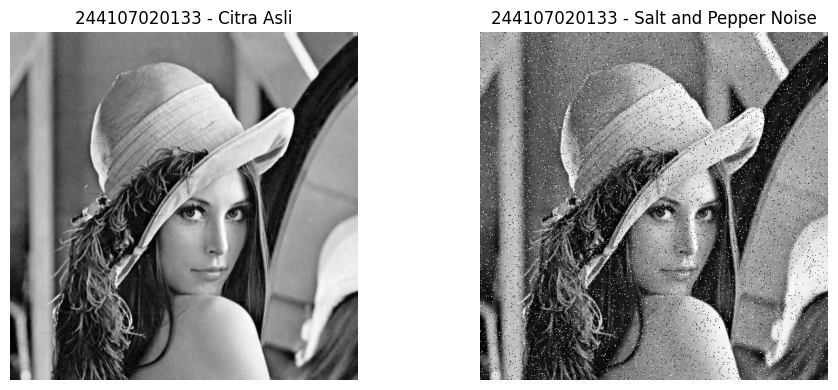

In [19]:
# Tugas 1a - Menambahkan Salt and Pepper Noise

img = cv.imread('/content/drive/MyDrive/PCVK/Images/lena.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

def add_salt_pepper_noise(image, amount=0.05):
    noisy = image.copy()

    jumlah_noise = int(amount * image.size)

    # Salt / putih
    y_salt = np.random.randint(0, image.shape[0], jumlah_noise // 2)
    x_salt = np.random.randint(0, image.shape[1], jumlah_noise // 2)
    noisy[y_salt, x_salt] = 255

    # Pepper / hitam
    y_pepper = np.random.randint(0, image.shape[0], jumlah_noise // 2)
    x_pepper = np.random.randint(0, image.shape[1], jumlah_noise // 2)
    noisy[y_pepper, x_pepper] = 0

    return noisy

img_noise = add_salt_pepper_noise(gray, 0.05)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title(NIM + ' - Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_noise, cmap='gray')
plt.title(NIM + ' - Salt and Pepper Noise')
plt.axis('off')

plt.tight_layout()
plt.show()

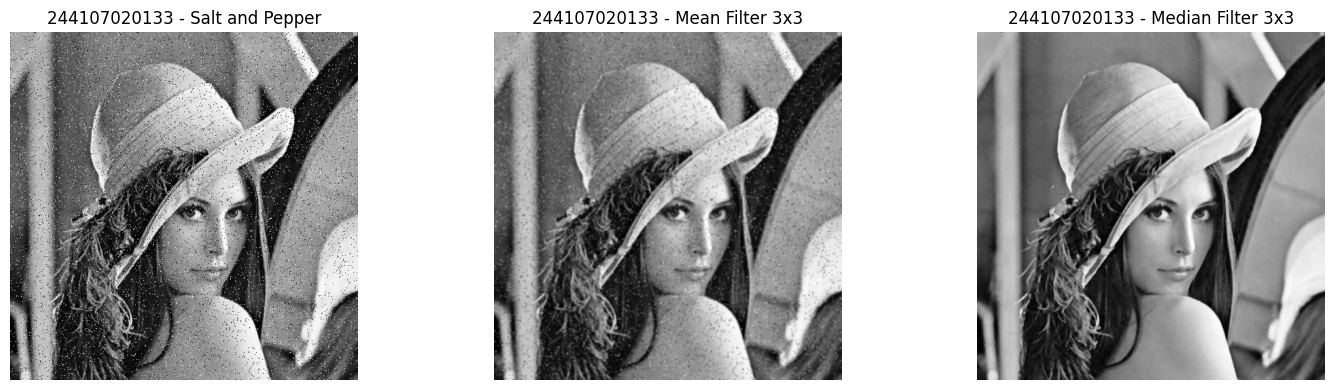

In [20]:
# Mean Filter 3x3
mean_filter = cv.blur(img_noise, (3, 3))

# Median Filter 3x3
median_filter = cv.medianBlur(img_noise, 3)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_noise, cmap='gray')
plt.title(NIM + ' - Salt and Pepper')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mean_filter, cmap='gray')
plt.title(NIM + ' - Mean Filter 3x3')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(median_filter, cmap='gray')
plt.title(NIM + ' - Median Filter 3x3')
plt.axis('off')

plt.tight_layout()
plt.show()

Berdasarkan hasil pengujian, Median Filter menghasilkan citra yang lebih bersih dibandingkan Mean Filter dalam menghilangkan noise Salt and Pepper. Median Filter bekerja dengan mengambil nilai median dari piksel-piksel di sekitar sehingga nilai ekstrem berupa piksel hitam dan putih dapat dihilangkan tanpa terlalu memengaruhi piksel normal. Sementara itu, Mean Filter menghitung nilai rata-rata piksel tetangga sehingga nilai noise masih ikut memengaruhi hasil dan menyebabkan citra menjadi lebih blur. Oleh karena itu, Median Filter lebih sesuai untuk menangani noise Salt and Pepper.

**TUGAS PRAKTIKUM 2**

In [21]:
# 2a. Buat kernel sharpening 3×3 dan 5×5
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

img_blur = cv.GaussianBlur(
    gray,
    (7, 7),
    2
)

kernel_sharpen_3x3 = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

kernel_sharpen_5x5 = np.array([
    [ 0,  0, -1,  0,  0],
    [ 0, -1, -1, -1,  0],
    [-1, -1, 13, -1, -1],
    [ 0, -1, -1, -1,  0],
    [ 0,  0, -1,  0,  0]
], dtype=np.float32)

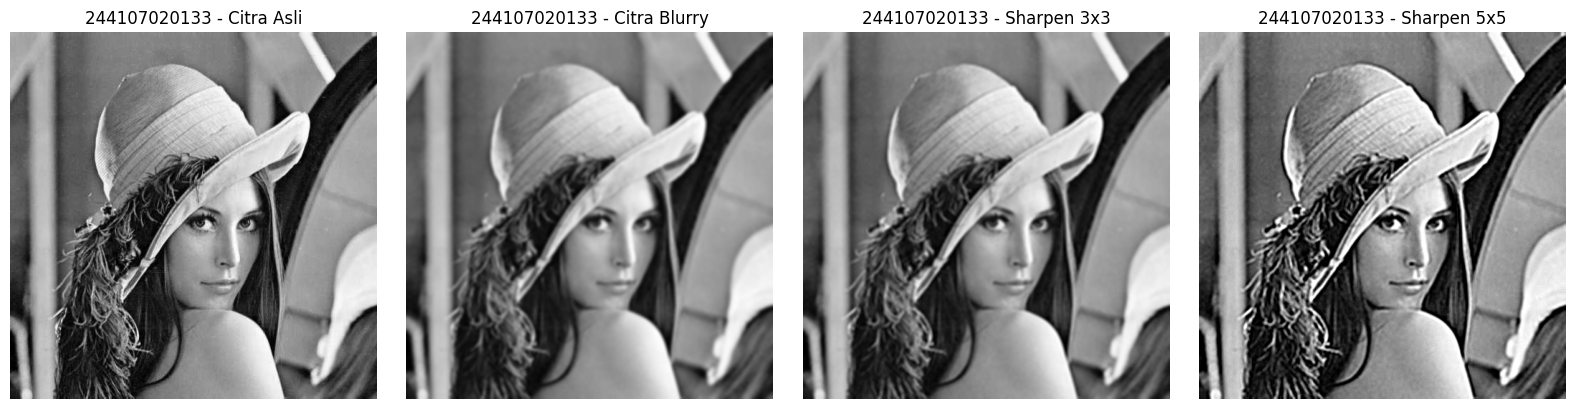

In [22]:
# 2b. Terapkan pada citra sedikit buram

hasil_3x3 = cv.filter2D(
    img_blur,
    -1,
    kernel_sharpen_3x3
)

hasil_5x5 = cv.filter2D(
    img_blur,
    -1,
    kernel_sharpen_5x5
)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.title(NIM + ' - Citra Asli')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(img_blur, cmap='gray')
plt.title(NIM + ' - Citra Blurry')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(hasil_3x3, cmap='gray')
plt.title(NIM + ' - Sharpen 3x3')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(hasil_5x5, cmap='gray')
plt.title(NIM + ' - Sharpen 5x5')
plt.axis('off')

plt.tight_layout()
plt.show()

2c. Evaluasi hasil

Kernel 3×3 menghasilkan penajaman yang lebih ringan dan mampu memperjelas tepi tanpa terlalu banyak menambah noise. Kernel 5×5 bekerja pada area yang lebih luas sehingga efek penajaman terlihat lebih kuat, tetapi dapat menyebabkan noise, halo, atau distorsi pada bagian tepi menjadi lebih terlihat. Berdasarkan keseimbangan antara kejelasan tepi dan noise yang dihasilkan, kernel 3×3 lebih optimal untuk penggunaan sehari-hari karena menghasilkan citra yang tetap tajam tetapi terlihat lebih natural.

**TUGAS PRAKTIKUM 3**

In [23]:
# 3a. Membuat fungsi kartun
def kartun(image):
    smooth = cv.bilateralFilter(image, 9, 75, 75)

    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

    gray_blur = cv.medianBlur(gray, 7)

    edge = cv.adaptiveThreshold(
        gray_blur,
        255,
        cv.ADAPTIVE_THRESH_MEAN_C,
        cv.THRESH_BINARY,
        9,
        9
    )

    hasil = cv.bitwise_and(
        smooth,
        smooth,
        mask=edge
    )

    return hasil


# Membaca citra
img_cartoon = cv.imread(
    '/content/drive/MyDrive/PCVK/Images/lena.jpg'
)

# Menjalankan fungsi kartun
hasil_kartun = kartun(img_cartoon)

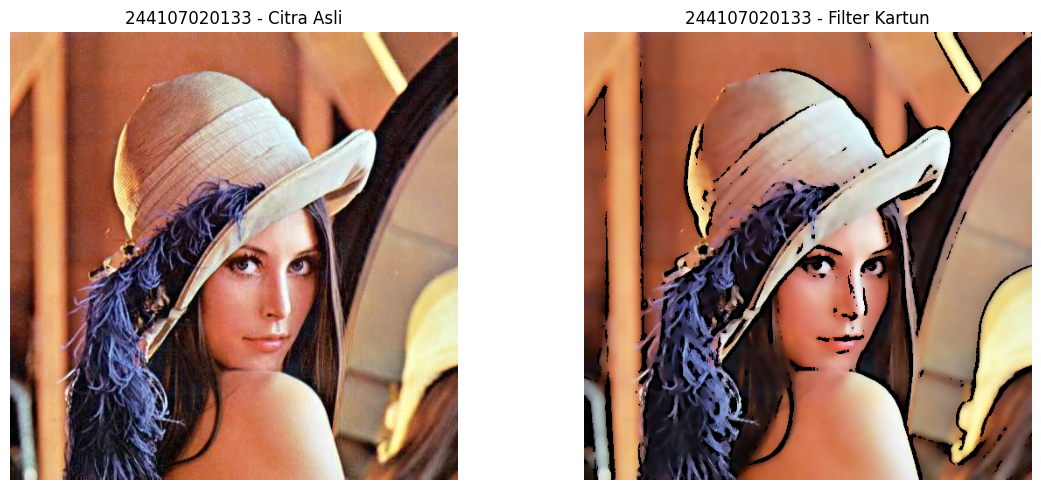

In [24]:
# 3b. Menampilkan citra asli dan hasil kartun
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img_cartoon, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Citra Asli')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(hasil_kartun, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - Filter Kartun')
plt.axis('off')

plt.tight_layout()
plt.show()